# PyCUDA and cuBLAS: dense matrix multiplication

Compute $C=AB$ for rectangular dense matrices. Compare all entries with NumPy, check selected entries as row-column dot products, and display the matrices and errors. The GPU product uses a library routine rather than a hand-written CUDA kernel.

Run cells in order in a Google Colab GPU runtime. All figures and printouts stay in the notebook; no result files are exported. This is an introductory correctness experiment, not a CPU/GPU speed benchmark.

PyCUDA owns the GPU arrays and transfers; **cuBLAS**, called through NVIDIA `nvmath.bindings`, performs the numerical operation. These bindings are a separate package, not part of PyCUDA. The examples do not call CuPy.

## 1. Prepare a fresh Google Colab GPU runtime

Choose **Runtime → Change runtime type → GPU**. Run the setup before imports. It installs PyCUDA and pins nvmath-python 1.0.0, with the CUDA 12 or 13 dependencies matching the runtime toolkit. Installation can take several minutes. A compatible NVIDIA driver and `nvcc` are still required. The low-level bindings are documented as experimental, so the package version is fixed rather than silently taking an arbitrary future release.

Use a fresh runtime for this notebook; do not mix `pycuda.autoinit` from an earlier notebook with the primary-context initialization used here.

In [1]:
import re
import subprocess
import sys
from importlib.metadata import version, PackageNotFoundError

# Run this cell before importing PyCUDA or nvmath in a fresh GPU runtime.
subprocess.run(["nvidia-smi"], check=True)
info = subprocess.check_output(["nvcc", "--version"], text=True)
print(info)
match = re.search(r"release\s+(\d+)\.", info)
if not match or int(match.group(1)) not in (12, 13):
    raise RuntimeError("This notebook setup targets CUDA 12 or 13.")
major = int(match.group(1))
requirements = ["pycuda", f"nvmath-python[cu{major}]==1.0.0"]
subprocess.check_call([sys.executable, "-m", "pip", "install", *requirements])
print("Setup complete. If Colab asks for a runtime restart, restart before proceeding.")

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0

Setup complete. If Colab asks for a runtime restart, restart before proceeding.


## 2. Imports and validation

The primary CUDA context is shared by the PyCUDA allocations and library calls. All work uses the default stream; the examples wait for completion before destroying library resources. Double precision and the same input formulas as in the CuPy notebook permit like-for-like correctness checks.

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoprimaryctx  # keep one primary context current for these libraries
import pycuda.gpuarray as gpuarray
import nvmath
from importlib.metadata import version

print("GPU:", cuda.Context.get_device().name())
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "PyCUDA:", version("pycuda"),
      "nvmath-python:", version("nvmath-python"))
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})

def ptr(a):
    # The owner must remain alive while the library uses its device storage.
    return int(a.gpudata)

GPU: Tesla T4
Python: 3.13.15
NumPy: 2.1.3 PyCUDA: 2026.1 nvmath-python: 1.0.0


In [3]:
def check(label, result, reference, rtol=1e-11, atol=1e-11):
    assert result.shape == reference.shape, (result.shape, reference.shape)
    assert result.dtype == reference.dtype, (result.dtype, reference.dtype)
    if not np.all(np.isfinite(result)):
        raise AssertionError(f"{label}: nonfinite result")
    np.testing.assert_allclose(result, reference, rtol=rtol, atol=atol)
    error = np.max(np.abs(result-reference))
    relative = np.linalg.norm((result-reference).ravel()) / max(np.linalg.norm(reference.ravel()), np.finfo(float).tiny)
    print(f"{label}: validated; max absolute error={error:.3e}; relative norm error={relative:.3e}")

### Library bridge: dense multiplication

Run this helper once. `dense_matmul_gpu` is notebook code, not a built-in PyCUDA matrix operator. cuBLAS `dgemm` computes a double-precision matrix product. Its traditional interface uses column-major storage. The helper keeps the row-major arrays used in the CuPy example and applies $C^T=B^TA^T$ by exchanging operands and dimensions in the library call. No actual transpose or extra data transfer is performed. The rectangular example checks this detail.

In [4]:
from nvmath.bindings import cublas

def dense_matmul_gpu(a, b):
    """C-contiguous float64 matrix product, returning a C-contiguous GPUArray."""
    if len(a.shape) != 2 or len(b.shape) != 2 or a.shape[1] != b.shape[0]:
        raise ValueError("Incompatible matrix dimensions")
    if any(x.dtype != np.float64 or not x.flags.c_contiguous for x in (a, b)):
        raise ValueError("Expected C-contiguous float64 arrays")
    m, k = a.shape
    n = b.shape[1]
    if min(m, n, k) < 1 or max(m, n, k) > np.iinfo(np.int32).max:
        raise ValueError("Dimensions must fit positive 32-bit integers")
    result = gpuarray.empty((m, n), np.float64)
    alpha, beta = np.array(1., dtype=np.float64), np.array(0., dtype=np.float64)
    handle = cublas.create()
    try:
        cublas.set_pointer_mode(handle, cublas.PointerMode.HOST)
        cublas.set_stream(handle, 0)
        # cuBLAS interprets these row-major buffers as transposed column-major
        # matrices. Compute C^T = B^T A^T without transposing or copying data.
        cublas.dgemm(handle, cublas.Operation.N, cublas.Operation.N,
                     n, m, k, alpha.ctypes.data,
                     ptr(b), n, ptr(a), k, beta.ctypes.data, ptr(result), n)
        cuda.Context.synchronize()
    finally:
        cublas.destroy(handle)
    return result

## 3. Prepare compatible rectangular matrices

Choose $A\in\mathbb{R}^{96\times64}$ and $B\in\mathbb{R}^{64\times80}$, giving $C\in\mathbb{R}^{96\times80}$. The deterministic formulas create visible structure without identical rows or columns. The shared inner dimension, 64, is the length of each dot product.

In [5]:
M, K, P = 96, 64, 80
r = np.arange(M,dtype=np.float64)[:,None]
k = np.arange(K,dtype=np.float64)[None,:]
h_A = np.sin(0.07*(r+1)*(k+1)) + 0.1*np.cos(0.19*r)
k_col = np.arange(K,dtype=np.float64)[:,None]
p = np.arange(P,dtype=np.float64)[None,:]
h_B = np.cos(0.05*(k_col+1)*(p+1)) + 0.2*np.sin(0.13*p)
h_A = np.ascontiguousarray(h_A)
h_B = np.ascontiguousarray(h_B)
C_cpu = h_A @ h_B
print("A:",h_A.shape,"B:",h_B.shape,"C:",C_cpu.shape)
print("Input dtypes:",h_A.dtype,h_B.dtype)

A: (96, 64) B: (64, 80) C: (96, 80)
Input dtypes: float64 float64


## 4. Compute the dense product

Transfer the input matrices once and call the helper, which passes their device pointers to cuBLAS. The result is a GPUArray and remains on the GPU until `.get()` retrieves it. No CUDA kernel or launch configuration is written for matrix multiplication.

`GPUArray` multiplication with `*` is elementwise; it does not replace the matrix-product library call.

In [6]:
d_A = gpuarray.to_gpu(h_A)
d_B = gpuarray.to_gpu(h_B)
d_C = dense_matmul_gpu(d_A, d_B)
C_gpu = d_C.get()
check("Dense matrix product", C_gpu, C_cpu,rtol=2e-11,atol=2e-11)

# An independent explicit dot product verifies selected output entries.
selected_entries = [(0,0),(M//2,P//2),(M-1,P-1)]
print(f"{'(row,col)':>14} {'GPU':>20} {'NumPy':>20} {'explicit dot':>20}")
for i,j in selected_entries:
    explicit_dot = sum(float(h_A[i,l])*float(h_B[l,j]) for l in range(K))
    np.testing.assert_allclose(C_gpu[i,j],explicit_dot,rtol=2e-11,atol=2e-11)
    print(f"{str((i,j)):>14} {C_gpu[i,j]:20.12f} {C_cpu[i,j]:20.12f} {explicit_dot:20.12f}")

Dense matrix product: validated; max absolute error=0.000e+00; relative norm error=0.000e+00
     (row,col)                  GPU                NumPy         explicit dot
        (0, 0)      21.541875833686      21.541875833686      21.541875833686
      (48, 40)       0.682707560535       0.682707560535       0.682707560535
      (95, 79)      -1.429266973463      -1.429266973463      -1.429266973463


## 5. Visualize the matrices and product error

Every pixel represents a matrix entry. A and B use a common color scale; the product has its own scale because it sums many products. The final panel shows the absolute difference from NumPy.

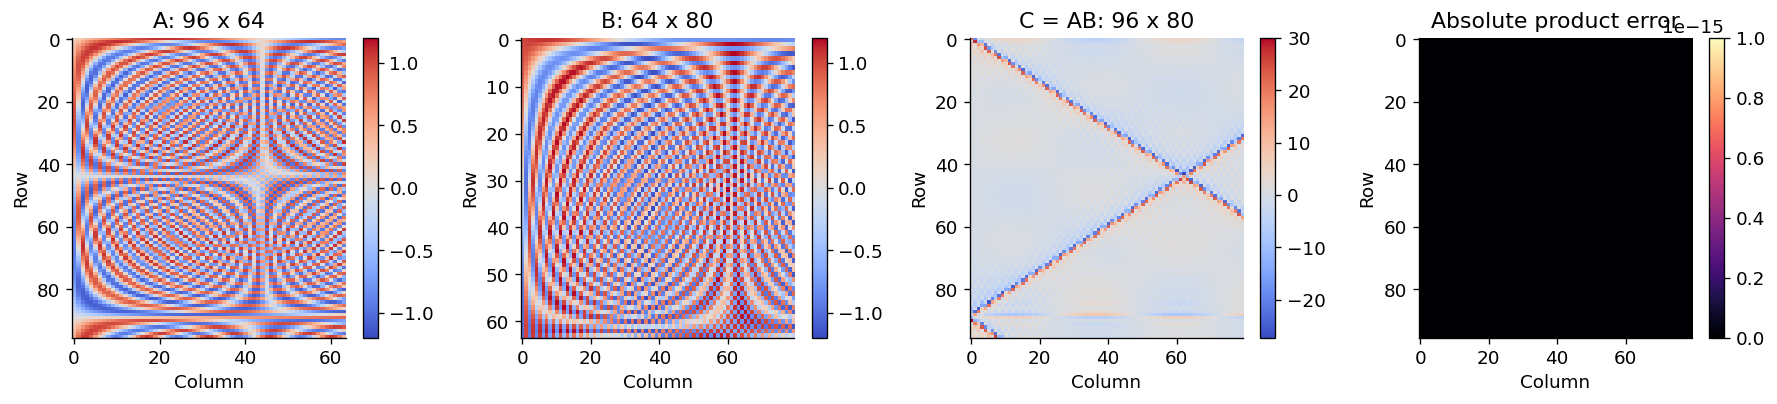

In [7]:
fig, axes=plt.subplots(1,4,figsize=(15,3.5))
limit=max(np.max(np.abs(h_A)),np.max(np.abs(h_B)))
for ax,matrix,title in zip(axes[:2],[h_A,h_B],[f'A: {M} x {K}',f'B: {K} x {P}']):
    im=ax.imshow(matrix,cmap='coolwarm',vmin=-limit,vmax=limit,aspect='auto')
    ax.set(title=title,xlabel='Column',ylabel='Row');fig.colorbar(im,ax=ax)
im=axes[2].imshow(C_gpu,cmap='coolwarm',aspect='auto')
axes[2].set(title=f'C = AB: {M} x {P}',xlabel='Column',ylabel='Row');fig.colorbar(im,ax=axes[2])
error = np.abs(C_gpu-C_cpu)
im=axes[3].imshow(error,cmap='magma',aspect='auto',vmin=0,
                  vmax=max(float(error.max()),1e-15))
axes[3].set(title='Absolute product error',xlabel='Column',ylabel='Row');fig.colorbar(im,ax=axes[3])
fig.tight_layout();plt.show()

## 6. A small example: matrix versus elementwise multiplication

Use square arrays so that both operations are legal. The different answers make the distinction visible. For C=AB, each output is a row-column dot product; elementwise multiplication uses only the two entries at the same location.

In [8]:
small_A = np.array([[1.,2.],[3.,4.]],dtype=np.float64)
small_B = np.array([[5.,6.],[7.,8.]],dtype=np.float64)
ds_A, ds_B = gpuarray.to_gpu(small_A), gpuarray.to_gpu(small_B)
small_matmul = dense_matmul_gpu(ds_A, ds_B).get()
small_elementwise = (ds_A * ds_B).get()
check("Small matrix product",small_matmul,np.array([[19.,22.],[43.,50.]]))
check("Small elementwise product",small_elementwise,np.array([[5.,12.],[21.,32.]]))
print("A @ B (matrix product):\n",small_matmul)
print("A * B (elementwise product):\n",small_elementwise)

Small matrix product: validated; max absolute error=0.000e+00; relative norm error=0.000e+00
Small elementwise product: validated; max absolute error=0.000e+00; relative norm error=0.000e+00
A @ B (matrix product):
 [[19. 22.]
 [43. 50.]]
A * B (elementwise product):
 [[ 5. 12.]
 [21. 32.]]


## Interpretation and execution status

The arrays are owned by PyCUDA; the numerical operation is executed by the named NVIDIA library through nvmath bindings. Plan creation, handles, descriptors, and workspaces are explicit here, whereas CuPy normally manages them behind its array interface. These teaching helpers deliberately synchronize before releasing resources; they are not benchmark harnesses or optimized repeated-operation wrappers. A production solver would reuse compatible plans, handles, buffers and descriptors.

**Preparation status:** code syntax, CPU reference calculations, data-layout checks and plotting logic were checked. GPU execution and Colab package installation could not be tested in the preparation environment. No GPU outputs or timings are prefilled.

References: [PyCUDA GPUArray](https://documen.tician.de/pycuda/array.html), [NVIDIA nvmath bindings](https://docs.nvidia.com/cuda/nvmath-python/latest/bindings/index.html), [installation](https://docs.nvidia.com/cuda/nvmath-python/latest/installation.html).

## Cleanup

Library handles and descriptors are released by the helper functions after completion. Remove the remaining device arrays below. To repeat the experiment, rerun from data preparation.

In [9]:
cuda.Context.synchronize()
del d_A, d_B, d_C, ds_A, ds_B
print("Device array references released.")

Device array references released.
